In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

#Fathur Rasyid Irimawa 202431036

In [2]:
dataset = pd.read_csv('train.csv')
dataset.head()

#Fathur Rasyid Irimawa 202431036

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


In [3]:
dataset.info()

#Fathur Rasyid Irimawa 202431036

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_sc

In [4]:
dataset.describe()

#Fathur Rasyid Irimawa 202431036

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [5]:
print("isna().sum() SEBELUM pembersihan:")
print(dataset.isna().sum())
print("Jumlah duplikat:", dataset.duplicated().sum())

print("\nJumlah nilai 0 pada sc_w      :", (dataset['sc_w'] == 0).sum())
print("Jumlah nilai 0 pada px_height :", (dataset['px_height'] == 0).sum())

#Fathur Rasyid Irimawa 202431036

isna().sum() SEBELUM pembersihan:
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64
Jumlah duplikat: 0

Jumlah nilai 0 pada sc_w      : 180
Jumlah nilai 0 pada px_height : 2


In [6]:
for kolom in ['sc_w', 'px_height']:
    dataset[kolom] = dataset[kolom].replace(0, np.nan)
    dataset[kolom] = dataset[kolom].fillna(dataset[kolom].median())

print("isna().sum() SESUDAH pembersihan:")
print(dataset.isna().sum())
print("Sisa nilai 0 pada sc_w/px_height:", (dataset[['sc_w', 'px_height']] == 0).sum().sum())

#Fathur Rasyid Irimawa 202431036

isna().sum() SESUDAH pembersihan:
battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64
Sisa nilai 0 pada sc_w/px_height: 0


In [7]:
print(dataset['price_range'].unique())
print(dataset['price_range'].value_counts().sort_index())

# Arti kelas price_range:
# 0 = harga rendah (low cost)
# 1 = harga menengah (medium cost)
# 2 = harga tinggi (high cost)
# 3 = harga sangat tinggi (very high cost)

#Fathur Rasyid Irimawa 202431036

[1 2 3 0]
0    500
1    500
2    500
3    500
Name: price_range, dtype: int64


In [8]:
le = LabelEncoder()
dataset['price_encoded'] = le.fit_transform(dataset['price_range'])

for kode, kelas in enumerate(le.classes_):
    print(kode, '->', kelas)

#Fathur Rasyid Irimawa 202431036

0 -> 0
1 -> 1
2 -> 2
3 -> 3


In [9]:
x = dataset.drop(columns=['price_range', 'price_encoded'], errors='ignore')
y = dataset['price_encoded']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=0)

print("Data latih:", x_train.shape, "| Data uji:", x_test.shape)
print("\nProporsi kelas data latih:\n", y_train.value_counts(normalize=True).sort_index().round(3))
print("\nProporsi kelas data uji:\n", y_test.value_counts(normalize=True).sort_index().round(3))

#Fathur Rasyid Irimawa 202431036

Data latih: (1400, 20) | Data uji: (600, 20)

Proporsi kelas data latih:
 0    0.249
1    0.261
2    0.249
3    0.241
Name: price_encoded, dtype: float64

Proporsi kelas data uji:
 0    0.252
1    0.225
2    0.252
3    0.272
Name: price_encoded, dtype: float64


In [10]:
pipeline = Pipeline([('scaler', StandardScaler()), ('svc', SVC())])

#Fathur Rasyid Irimawa 202431036

In [11]:
params = {
    'svc__kernel' : ['linear', 'rbf', 'poly'],
    'svc__C' : [0.1, 1, 10, 100],
    'svc__gamma' : ['scale', 0.01, 0.1, 1]
}

jumlah_kombinasi = len(params['svc__kernel']) * len(params['svc__C']) * len(params['svc__gamma'])
print("Jumlah kombinasi:", jumlah_kombinasi, "(3 kernel x 4 C x 4 gamma)")
print("Total fit dengan cv=5:", jumlah_kombinasi * 5)

#Fathur Rasyid Irimawa 202431036

Jumlah kombinasi: 48 (3 kernel x 4 C x 4 gamma)
Total fit dengan cv=5: 240


In [12]:
grid_search = GridSearchCV(
    estimator = pipeline,
    param_grid = params,
    scoring = 'accuracy',
    cv = 5,
    n_jobs = 1,
    verbose = 1
)

grid_search.fit(x_train, y_train)
print("Grid Search Done!")
print("Best params: ", grid_search.best_params_)
print("Best CV score: ", grid_search.best_score_)

#Fathur Rasyid Irimawa 202431036

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Grid Search Done!
Best params:  {'svc__C': 100, 'svc__gamma': 'scale', 'svc__kernel': 'linear'}
Best CV score:  0.9678571428571429


In [13]:
hasil = pd.DataFrame(grid_search.cv_results_)
kolom = ['param_svc__kernel', 'param_svc__C', 'param_svc__gamma',
         'mean_test_score', 'std_test_score', 'rank_test_score']

peringkat1 = hasil[hasil['rank_test_score'] == 1][kolom]
print("Jumlah kandidat peringkat 1:", len(peringkat1))
peringkat1

#Fathur Rasyid Irimawa 202431036

Jumlah kandidat peringkat 1: 4


,param_svc__kernel,param_svc__C,param_svc__gamma,mean_test_score,std_test_score,rank_test_score
36,linear,100,scale,0.967857,0.005051,1
39,linear,100,0.01,0.967857,0.005051,1
42,linear,100,0.1,0.967857,0.005051,1
45,linear,100,1,0.967857,0.005051,1


In [14]:
urutan_kernel = {'linear': 0, 'rbf': 1, 'poly': 2}
pilihan = (peringkat1
           .assign(k_rank = peringkat1['param_svc__kernel'].map(urutan_kernel),
                   g_rank = (peringkat1['param_svc__gamma'] != 'scale').astype(int))
           .sort_values(['param_svc__C', 'k_rank', 'g_rank'])
           .iloc[0])

print("Model akhir:", pilihan['param_svc__kernel'], "| C =", pilihan['param_svc__C'],
      "| gamma =", pilihan['param_svc__gamma'])

best_model = pipeline.set_params(svc__kernel = pilihan['param_svc__kernel'],
                                 svc__C = float(pilihan['param_svc__C']),
                                 svc__gamma = pilihan['param_svc__gamma'])
best_model.fit(x_train, y_train)

#Fathur Rasyid Irimawa 202431036

Model akhir: linear | C = 100 | gamma = scale


Pipeline(steps=[('scaler', StandardScaler()),
                ('svc', SVC(C=100.0, kernel='linear'))])

In [15]:
y_train_pred = best_model.predict(x_train)
y_test_pred = best_model.predict(x_test)

print("Train Accuracy: ", accuracy_score(y_train, y_train_pred))
print("Test Accuracy: ", accuracy_score(y_test, y_test_pred))

#Fathur Rasyid Irimawa 202431036

Train Accuracy:  0.9914285714285714
Test Accuracy:  0.9616666666666667


In [16]:
print("Confusion Matrix (test): \n", confusion_matrix(y_test, y_test_pred))
print("\nClassification Report (test): \n",
      classification_report(y_test, y_test_pred, target_names=['0 rendah', '1 menengah', '2 tinggi', '3 sangat tinggi']))

#Fathur Rasyid Irimawa 202431036

Confusion Matrix (test): 
 [[147   4   0   0]
 [  4 127   4   0]
 [  0   5 143   3]
 [  0   0   3 160]]

Classification Report (test): 
                  precision    recall  f1-score   support

       0 rendah       0.97      0.97      0.97       151
     1 menengah       0.93      0.94      0.94       135
       2 tinggi       0.95      0.95      0.95       151
3 sangat tinggi       0.98      0.98      0.98       163

       accuracy                           0.96       600
      macro avg       0.96      0.96      0.96       600
   weighted avg       0.96      0.96      0.96       600



In [17]:
print(dataset[['ram', 'battery_power', 'price_range']].corr()['price_range'])

mask = dataset['price_range'].isin([0, 3])
x2 = dataset.loc[mask, ['ram', 'battery_power']]
y2 = dataset.loc[mask, 'price_range']

scaler2 = StandardScaler()
x2_s = scaler2.fit_transform(x2)

svm2 = SVC(kernel='linear', C=1000)
svm2.fit(x2_s, y2)

w = svm2.coef_[0]
b = svm2.intercept_[0]
print("coef_      :", svm2.coef_)
print("intercept_ :", svm2.intercept_)
print("n_support_ :", svm2.n_support_)
print("Akurasi    :", svm2.score(x2_s, y2))
print("Margin 2/||w|| =", 2 / np.linalg.norm(w))

#Fathur Rasyid Irimawa 202431036

ram              0.917046
battery_power    0.200723
price_range      1.000000
Name: price_range, dtype: float64
coef_      : [[3.55958945 0.73603332]]
intercept_ : [0.22189431]
n_support_ : [1 2]
Akurasi    : 1.0
Margin 2/||w|| = 0.5502230441701257


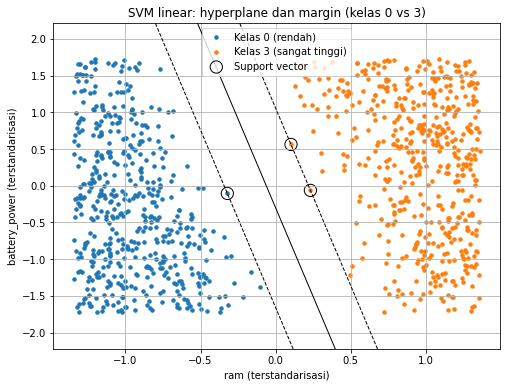

In [18]:
plt.figure(figsize=(8, 6))
plt.scatter(x2_s[y2 == 0, 0], x2_s[y2 == 0, 1], s=12, label='Kelas 0 (rendah)')
plt.scatter(x2_s[y2 == 3, 0], x2_s[y2 == 3, 1], s=12, label='Kelas 3 (sangat tinggi)')
plt.scatter(svm2.support_vectors_[:, 0], svm2.support_vectors_[:, 1],
            s=150, facecolors='none', edgecolors='k', label='Support vector')

xs = np.linspace(x2_s[:, 0].min(), x2_s[:, 0].max(), 100)
for nilai, gaya in [(0, '-'), (1, '--'), (-1, '--')]:
    plt.plot(xs, (nilai - b - w[0] * xs) / w[1], 'k' + gaya, linewidth=1)

plt.ylim(x2_s[:, 1].min() - 0.5, x2_s[:, 1].max() + 0.5)
plt.xlabel("ram (terstandarisasi)")
plt.ylabel("battery_power (terstandarisasi)")
plt.title("SVM linear: hyperplane dan margin (kelas 0 vs 3)")
plt.legend()
plt.grid(True)
plt.show()

#Fathur Rasyid Irimawa 202431036